# ENDICEX — Análisis de componentes principales (PCA) y selección del número de clústeres

### 1. Objetivo

Este cuaderno desarrolla el análisis multivariante de la muestra exploratoria de **111 entidades locales** del proyecto ENDICEX, mediante dos análisis de componentes principales (PCA) y la evaluación del número de agrupaciones para la posterior aplicación de K-means.

El procedimiento comprende:

- **PCA socioeconómico:** reducción de las variables de pobreza y renta media por persona a una componente sintética de vulnerabilidad socioeconómica.
- **PCA financiero:** caracterización de las desviaciones relativas de endeudamiento, gasto e inversión por habitante mediante componentes principales.
- **Construcción de la matriz multidimensional:** integración de la componente socioeconómica y de las dos primeras componentes financieras.
- **Diagnóstico del número de clústeres:** evaluación de distintas soluciones mediante el método del codo y el coeficiente de silueta.

### 2. Datos de entrada

Se utiliza el archivo seudonimizado de ENDICEX, en la hoja `Muestra_111`, que contiene los indicadores socioeconómicos y financieros de las 111 entidades seleccionadas.

Los valores pendientes de endeudamiento por habitante (`END HAB`) han sido tratados previamente mediante un procedimiento independiente de imputación por medianas estratificadas, documentado en otro cuaderno.

**Este notebook no realiza nuevas imputaciones ni modifica los datos originales.**

### 3. Población de análisis

El PCA socioeconómico comprende las 111 entidades de la muestra.

El PCA financiero y la matriz utilizada para evaluar las agrupaciones se construyen sobre las observaciones que cumplen los criterios de disponibilidad y validez de la información financiera.

La selección de observaciones se realiza mediante reglas explícitas y verificables, documentándose el número de entidades efectivamente incorporadas a cada análisis.

### 4. Tratamiento estadístico

Las variables se transforman mediante procedimientos de normalización y análisis de componentes principales.

En el bloque financiero, el endeudamiento se analiza considerando las desviaciones superiores respecto de la mediana, mientras que el gasto y la inversión se caracterizan mediante sus desviaciones absolutas.

La matriz resultante integra una dimensión socioeconómica y dos financieras, con una ponderación equilibrada de ambos bloques.

No se eliminan automáticamente observaciones atípicas ni se interpretan las desviaciones estadísticas como irregularidades de gestión.

### 5. Diagnóstico de agrupaciones

Se comparan distintas soluciones de agrupamiento mediante el método del codo y el coeficiente de silueta.

Estos indicadores aportan evidencia sobre la cohesión y separación de los grupos, pero no determinan por sí solos el número óptimo de clústeres.

La selección definitiva debe considerar también la estabilidad de las agrupaciones, su tamaño y su interpretabilidad para la fiscalización pública.

### 6. Integridad y reproducibilidad

El procedimiento conserva el archivo original y trabaja sobre una copia de los datos en memoria.

Las transformaciones estadísticas, los parámetros utilizados y las comprobaciones de integridad se documentan para facilitar la revisión independiente y la reproducción de los resultados.

Los resultados tienen carácter exclusivamente investigador y exploratorio y no constituyen hallazgos de fiscalización.

## 1. Carga y verificación de la matriz de 111 entidades

Se utilizan exclusivamente los registros de la pestaña **`Muestra_111`** y se conservan los códigos INE como texto para no perder ceros iniciales. Se comprueba la integridad de la muestra, el estado de rendición, la información social y las imputaciones ya existentes de Navarra y País Vasco. **No se recalculan ni modifican las medianas previamente imputadas.**

Los valores financieros iguales a cero de ayuntamientos sin cuentas de 2024 se tratan como *no disponibles* en una copia destinada al modelo; el Excel original se preserva. La conciliación `GASTO MUNICIPAL / población` frente a `GTO HAB` genera alertas sin corregir automáticamente el dato fuente.

In [1]:

### 1. Bibliotecas y configuración
# ENDICEX: lectura de la muestra nacional seudonimizada.
# Se utiliza el Excel con las imputaciones de END HAB ya realizadas.
# El archivo original no se modifica.

import io
import numpy as np
import pandas as pd
from google.colab import files
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

SEMILLA_KMEANS = 42
COL_FIN = ['END HAB', 'GTO HAB', 'INV POR HAB']


### 2. Carga del archivo Excel
# Se leen la muestra y la hoja de auditoría de imputaciones.

print('Sube el Excel ENDICEX con END HAB imputado.')
archivos = files.upload()

if len(archivos) != 1:
    raise ValueError('Selecciona exactamente un archivo Excel.')

nombre_entrada, contenido = next(iter(archivos.items()))
libro = pd.ExcelFile(io.BytesIO(contenido))

D = pd.read_excel(
    libro, sheet_name='Muestra_111',
    dtype={'codigo_ine': str}
)

auditoria = pd.read_excel(
    libro, sheet_name='Auditoria_END_HAB',
    dtype={'codigo_ine': str}
)


### 3. Validación de la muestra
# Se comprueban los 111 registros, sus identificadores
# y la disponibilidad de las variables necesarias.

D.columns = D.columns.str.strip()
D['codigo_ine'] = (
    D['codigo_ine'].astype('string')
    .str.strip()
    .str.replace(r'\.0$', '', regex=True)
    .str.zfill(5)
)

obligatorias = {
    'codigo_ine', 'id_aleatorio', 'tipo_entidad',
    'poblacion', 'estrato', 'renta_media_persona',
    'pobreza_total_60', 'gini', 'cuentas 24',
    'Cuentas 23', 'falta rendición',
    'GASTO MUNICIPAL', *COL_FIN
}

faltantes = obligatorias - set(D.columns)

if faltantes:
    raise ValueError(f'Faltan columnas: {sorted(faltantes)}')

if (
    len(D) != 111
    or D['codigo_ine'].nunique() != 111
    or D['id_aleatorio'].nunique() != 111
    or D['codigo_ine'].isna().any()
    or D['id_aleatorio'].isna().any()
):
    raise ValueError('La muestra no contiene 111 entidades únicas.')


### 4. Normalización de variables
# Se convierten los indicadores a formato numérico.
# Las celdas ausentes se conservan como NaN.

numericas = [
    'poblacion', 'renta_media_persona',
    'pobreza_total_60', 'gini',
    'cuentas 24', 'Cuentas 23', 'falta rendición',
    'GASTO MUNICIPAL', *COL_FIN
]

for c in numericas:
    D[c] = pd.to_numeric(
        D[c].astype('string').str.replace(',', '.', regex=False),
        errors='coerce'
    )

if D[['poblacion', 'renta_media_persona',
      'pobreza_total_60', 'gini']].isna().any().any():
    raise ValueError('Existen datos socioeconómicos ausentes.')

if D['poblacion'].le(0).any():
    raise ValueError('Se han encontrado poblaciones no positivas.')

if not D['cuentas 24'].isin([0, 1]).all():
    raise ValueError('Revisar los estados de rendición de 2024.')

if not D['falta rendición'].isin([0, 0.5, 1]).all():
    raise ValueError('Revisar los indicadores de falta de rendición.')


### 5. Identificación de regímenes singulares e imputaciones
# Ceuta y Melilla se identifican, pero permanecen
# en la base. Su inclusión en cada PCA se decide
# en la correspondiente etapa metodológica.
#
# Las imputaciones se identifican desde la hoja
# de auditoría, sin enumerar códigos INE manualmente.

D['regimen_singular'] = D['codigo_ine'].isin(
    ['51001', '52001']
)

codigos_imputados = (
    auditoria['codigo_ine'].astype('string')
    .str.strip()
    .str.replace(r'\.0$', '', regex=True)
    .str.zfill(5)
)

if (
    codigos_imputados.isna().any()
    or codigos_imputados.duplicated().any()
    or not codigos_imputados.isin(D['codigo_ine']).all()
):
    raise ValueError('Incoherencias en la auditoría de imputaciones.')

D['END_HAB_imputado'] = D['codigo_ine'].isin(
    codigos_imputados
)

if D['END_HAB_imputado'].sum() != len(auditoria):
    raise ValueError('No coinciden los registros imputados.')


### 6. Preparación de los datos financieros
# Se crea una copia para el modelo.
# Las entidades sin cuentas rendidas en 2024 no
# deben aportar valores financieros al PCA.
# Los datos de origen permanecen intactos.

D_modelo = D.copy()
D_modelo.loc[D_modelo['cuentas 24'].ne(1), COL_FIN] = np.nan


### 7. Control de coherencia del gasto por habitante
# Se compara GTO HAB con GASTO MUNICIPAL / población.
# Las desviaciones superiores al 10 % se señalan
# para revisión, sin corregir automáticamente el dato.

gasto_recalculado = D['GASTO MUNICIPAL'] / D['poblacion']

D['revisar_gto_hab'] = (
    D['cuentas 24'].eq(1)
    & D['GTO HAB'].gt(0)
    & gasto_recalculado.gt(0)
    & (
        (D['GTO HAB'] - gasto_recalculado).abs()
        / gasto_recalculado
    ).gt(0.10)
)


### 8. Resumen de controles
print('Archivo:', nombre_entrada)
print('Entidades:', len(D))
print('Cuentas 2024 rendidas:', int(D['cuentas 24'].eq(1).sum()))
print('Sin cuentas 2024:', int(D['cuentas 24'].eq(0).sum()))
print('END HAB imputados:', int(D['END_HAB_imputado'].sum()))
print('Alertas de gasto por habitante:', int(D['revisar_gto_hab'].sum()))


Sube el Excel ENDICEX con END HAB imputado.


Saving ENDICEX_111_Anonimo_END_HAB_Imputado.xlsx to ENDICEX_111_Anonimo_END_HAB_Imputado.xlsx
Archivo: ENDICEX_111_Anonimo_END_HAB_Imputado.xlsx
Entidades: 111
Cuentas 2024 rendidas: 101
Sin cuentas 2024: 10
END HAB imputados: 8
Alertas de gasto por habitante: 12



## 2. PCA socioeconómico (111 entidades)

Se aplica un análisis de componentes principales (PCA) a dos indicadores: **pobreza total** y **renta media neta por persona con signo invertido**, previa tipificación robusta mediante mediana y rango intercuartílico (IQR).

La primera componente (CP1) se orienta de forma que sus valores más elevados indiquen mayor vulnerabilidad socioeconómica relativa. El índice de Gini se reserva para caracterizar los perfiles, sin intervenir en el PCA social.

Adicionalmente, se aplica K-means (K=3) sobre CP1 para obtener una clasificación social auxiliar de las 111 entidades, ordenada de menor (S1) a mayor vulnerabilidad económico social (S3), independiente del clustering multidimensional posterior.


In [3]:

### 2. PCA socioeconómico (111 entidades)
# Se utilizan pobreza total y renta media invertida.
# El índice de Gini no interviene en el PCA social.

### 2.1. Tipificación robusta
# Centrado por mediana y escalado por rango intercuartílico (IQR).

def tipificacion_robusta(a):
    a = np.asarray(a,dtype=float)
    mediana = np.median(a,axis=0)
    iqr = np.percentile(a,75,axis=0) - np.percentile(a,25,axis=0)
    if np.any(iqr <= 0):
        raise ValueError(f'IQR nulo en una variable: {iqr}')
    return (a-mediana)/iqr, mediana, iqr


### 2.2. Construcción del PCA social
# La pobreza aumenta la vulnerabilidad económico-social (VSE) y la renta se invierte.
# CP1 se orienta para que sus valores altos indiquen
# mayor VSE relativa.

social_original = np.column_stack([D['pobreza_total_60'], -D['renta_media_persona']])
social_rob, med_social, iqr_social = tipificacion_robusta(social_original)
pca_social = PCA(n_components=2).fit(social_rob)
cp1_social = pca_social.transform(social_rob)[:,0]
if np.corrcoef(cp1_social, D['pobreza_total_60'])[0,1] < 0:
    cp1_social = -cp1_social
D['CP1_social'] = cp1_social


### 2.3. Clasificación social auxiliar (S1–S3)
# K-means unidimensional sobre CP1.
# Los grupos se ordenan de menor a mayor VSE.
# Esta clasificación no equivale a los clústeres K1–K5.

km_social = KMeans(n_clusters=3, random_state=SEMILLA_KMEANS, n_init=50).fit(cp1_social.reshape(-1,1))
orden_s = sorted(range(3),key=lambda j: np.median(cp1_social[km_social.labels_ == j]))
claves_s = {j:f'S{i+1}' for i,j in enumerate(orden_s)}
D['cluster_social'] = [claves_s[j] for j in km_social.labels_]


### 2.4. Resultados
# Varianza explicada por CP1 y distribución de los grupos.

print(f'PCA social: CP1 explica {pca_social.explained_variance_ratio_[0]:.1%} de la varianza.')
print('S1/S2/S3 (de menor a mayor VSE):',D['cluster_social'].value_counts().sort_index().to_dict())


PCA social: CP1 explica 92.7% de la varianza.
S1/S2/S3 (de menor a mayor VSE): {'S1': 13, 'S2': 56, 'S3': 42}



## 2.1. Interpretación del PCA socioeconómico

Se presentan los resultados del PCA aplicado a **111 entidades**, utilizando dos indicadores: pobreza total (umbral del 60 % de la mediana) y renta media neta por persona invertida, previamente tipificados mediante mediana e IQR.

La CP1 se orienta para que los valores más elevados indiquen mayor vulnerabilidad socioeconómica relativa. El índice de Gini se conserva como descriptor, sin intervenir en el PCA.

Se examinan la **varianza explicada, los coeficientes de los vectores propios, las contribuciones porcentuales y las correlaciones** entre las variables transformadas y las componentes. Estas magnitudes se presentan separadamente para evitar confundir coeficientes y correlaciones.

Únicamente la **CP1 social** se incorpora a la matriz multidimensional utilizada posteriormente para K-means. La CP2 se conserva con fines descriptivos.


In [4]:

### 2.1. Interpretación del PCA socioeconómico
# Cuadro de varianza explicada, cargas, contribuciones
# y correlaciones. No se vuelve a ajustar el PCA.

import numpy as np
import pandas as pd
from IPython.display import display, Markdown


### 2.1.1. Comprobación de variables
# Requiere haber ejecutado previamente el PCA social.

requeridas = ['D','pca_social','social_rob','social_original','med_social','iqr_social','cp1_social']
faltan = [v for v in requeridas if v not in globals()]
if faltan:
    raise RuntimeError('Faltan variables del PCA social; ejecuta primero la celda #2: '+', '.join(faltan))


### 2.1.2. Orientación de componentes y cargas
# Se mantiene la orientación de CP1 utilizada en el
# análisis: valores altos = mayor vulnerabilidad económico social relativa.
# No se modifica el PCA ajustado.

score_social_raw = pca_social.transform(social_rob)
social_signo = 1.0 if np.corrcoef(score_social_raw[:, 0], cp1_social)[0, 1] >= 0 else -1.0
scores_social_orientados = score_social_raw.copy()
scores_social_orientados[:, 0] *= social_signo
cargas_social_orientadas = pca_social.components_.copy()
cargas_social_orientadas[0] *= social_signo


### 2.1.3. Varianza explicada
# Se presentan CP1 y CP2, sus autovalores y
# la varianza explicada individual y acumulada.

var_social = pd.DataFrame({
    'Componente': ['CP1 social', 'CP2 social'],
    'Varianza explicada (%)': 100 * pca_social.explained_variance_ratio_,
    'Varianza acumulada (%)': 100 * np.cumsum(pca_social.explained_variance_ratio_),
    'Autovalor': pca_social.explained_variance_,
    'Uso posterior': ['Eje social de K-means', 'Solo descripción; no entra en K-means']
})


### 2.1.4. Coeficientes, contribuciones y correlaciones
# Los coeficientes son los elementos de los vectores
# propios; sus cuadrados expresan la contribución
# porcentual de cada variable a la componente.
# Las correlaciones se calculan por separado.

nombres_soc = ['Pobreza total (60 % mediana)', 'Renta media por persona (invertida)']
corr_soc = np.corrcoef(np.column_stack([social_rob, scores_social_orientados]).T)[:2, 2:]
contrib_soc = 100 * cargas_social_orientadas**2

variables_social = pd.DataFrame({
    'Variable transformada': nombres_soc,
    'Mediana de entrada': med_social,
    'IQR de entrada': iqr_social,
    'Coeficiente CP1': cargas_social_orientadas[0],
    'Contribución CP1 (%)': contrib_soc[0],
    'Correlación con CP1': corr_soc[:, 0],
    'Coeficiente CP2': cargas_social_orientadas[1],
    'Contribución CP2 (%)': contrib_soc[1],
    'Correlación con CP2': corr_soc[:, 1]
})


### 2.1.5. Presentación de resultados
# Cuadro A: varianza explicada.
# Cuadro B: interpretación de las variables.

print('CUADRO 2.1 | PCA SOCIOECONÓMICO')
print('Universo: %d entidades | Variables activas: 2 | Gini: solo descriptor' % len(D))
print('Preprocesamiento: (valor − mediana) / IQR; la renta se invierte antes del PCA.')
print('Orientación: CP1 alta = mayor privación relativa.')

display(Markdown('**A. Varianza explicada y utilidad de cada componente**'))
display(var_social.style.format({
    'Varianza explicada (%)':'{:.2f}',
    'Varianza acumulada (%)':'{:.2f}',
    'Autovalor':'{:.3f}'
}))

display(Markdown('**B. Cargas, contribuciones y correlaciones (variables robustamente transformadas)**'))
display(variables_social.style.format({
    c:'{:.3f}'
    for c in variables_social.columns
    if c != 'Variable transformada'
}))


### 2.1.6. Interpretación
# Síntesis de las componentes y sus magnitudes.

print('\nINTERPRETACIÓN:')
print('• CP1 social resume %.1f %% de la variación de las dos variables transformadas.' %
      (100*pca_social.explained_variance_ratio_[0]))
print('• Se ha orientado para que las puntuaciones positivas indiquen mayor privación;')
print('  la magnitud de las cargas y correlaciones permite identificar qué variable predomina.')
print('• CP2 social explica el %.1f %% restante y NO se incorpora a X.' %
      (100*pca_social.explained_variance_ratio_[1]))
print('• La contribución (%) es el cuadrado del coeficiente (suma 100 % por componente);')
print('  la correlación corresponde al eje y la variable transformada, no a los euros originales.')


CUADRO 2.1 | PCA SOCIOECONÓMICO
Universo: 111 entidades | Variables activas: 2 | Gini: solo descriptor
Preprocesamiento: (valor − mediana) / IQR; la renta se invierte antes del PCA.
Orientación: CP1 alta = mayor privación relativa.


**A. Varianza explicada y utilidad de cada componente**

,Componente,Varianza explicada (%),Varianza acumulada (%),Autovalor,Uso posterior
0,CP1 social,92.72,92.72,1.123,Eje social de K-means
1,CP2 social,7.28,100.00,0.088,Solo descripción; no entra en K-means


**B. Cargas, contribuciones y correlaciones (variables robustamente transformadas)**

,Variable transformada,Mediana de entrada,IQR de entrada,Coeficiente CP1,Contribución CP1 (%),Correlación con CP1,Coeficiente CP2,Contribución CP2 (%),Correlación con CP2
0,Pobreza total (60 % mediana),19.291,12.320,0.603,36.349,0.938,0.798,63.651,0.348
1,Renta media por persona (invertida),-14655.333,3559.364,0.798,63.651,0.978,-0.603,36.349,-0.207



INTERPRETACIÓN:
• CP1 social resume 92.7 % de la variación de las dos variables transformadas.
• Se ha orientado para que las puntuaciones positivas indiquen mayor privación;
  la magnitud de las cargas y correlaciones permite identificar qué variable predomina.
• CP2 social explica el 7.3 % restante y NO se incorpora a X.
• La contribución (%) es el cuadrado del coeficiente (suma 100 % por componente);
  la correlación corresponde al eje y la variable transformada, no a los euros originales.



## 3. Ingeniería de características (Feature engineering) y PCA financiero

El análisis financiero utiliza tres indicadores: **endeudamiento (`END HAB`), gasto (`GTO HAB`) e inversión (`INV POR HAB`) por habitante**.

Tras una tipificación robusta mediante mediana e IQR, se construyen tres características:

- **Endeudamiento:** `max(0, (END HAB − mediana) / IQR)`, considerando únicamente desviaciones superiores.
- **Gasto e inversión:** `abs((X − mediana) / IQR)`, considerando desviaciones en ambas direcciones.

Sobre estas características se aplica `StandardScaler` y un PCA de tres componentes. Se conservan las dos primeras componentes financieras (CP1 y CP2), cuya orientación se fija para facilitar la interpretación.

La matriz tridimensional `X` combina la primera componente social y las dos financieras, con un peso conjunto equilibrado entre ambas dimensiones.

En esta versión, el análisis financiero se restringe a ayuntamientos ordinarios con cuentas de 2024 rendidas e indicadores válidos. Ceuta y Melilla permanecen en la muestra general y en el PCA social.

**Las desviaciones estadísticas no constituyen, por sí mismas, irregularidades ni riesgos de fiscalización demostrados.**


In [10]:

### 3. Ingeniería de características y PCA financiero
# Se analizan los indicadores financieros de entidades
# con cuentas rendidas y valores válidos de 2024.


### 3.1. Selección de observaciones
# Se incluyen todas las entidades con cuentas de 2024
# rendidas e indicadores financieros completos y válidos.
# Ceuta y Melilla participan en el PCA y K-means.

validos = (
    D['cuentas 24'].eq(1) &
    D_modelo[COL_FIN].notna().all(axis=1) &
    D_modelo[COL_FIN].ge(0).all(axis=1)
)

if int(validos.sum()) < 10:
    raise ValueError('No hay suficientes entidades con datos financieros completos.')


### 3.2. Tipificación robusta
# Los tres indicadores se centran por mediana y
# se escalan mediante el rango intercuartílico (IQR).

fin_original = D_modelo.loc[validos, COL_FIN].to_numpy(dtype=float)
fin_rob, med_fin, iqr_fin = tipificacion_robusta(fin_original)


### 3.3. Ingeniería de características
# END HAB: solo desviaciones superiores a la mediana.
# GTO HAB e INV POR HAB: desviaciones absolutas
# respecto de la mediana, en ambas direcciones.

caract_fin = np.column_stack([
    np.maximum(0,fin_rob[:,0]),
    np.abs(fin_rob[:,1]),
    np.abs(fin_rob[:,2])
])


### 3.4. Estandarización y PCA financiero
# Se aplica StandardScaler antes del PCA.
# Se estiman tres componentes y se conservan las dos
# primeras para el clustering multidimensional.

caract_fin_std = StandardScaler().fit_transform(caract_fin)
pca_fin = PCA(n_components=3).fit(caract_fin_std)
componentes_fin = pca_fin.transform(caract_fin_std)
cargas_fin = pca_fin.components_.copy()


### 3.5. Orientación de las componentes
# CP1: orientación positiva hacia atipicidad de gasto.
# CP2: orientación positiva hacia endeudamiento elevado.
# Se mantiene la orientación del algoritmo original.

if cargas_fin[0,1] < 0:
    componentes_fin[:,0] *= -1
    cargas_fin[0,:] *= -1
if cargas_fin[1,0] < 0:
    componentes_fin[:,1] *= -1
    cargas_fin[1,:] *= -1


### 3.6. Incorporación de componentes financieras
# Se asignan CP1 y CP2 exclusivamente a las
# observaciones incluidas en el PCA financiero.

D['CP1_financiero'] = np.nan
D['CP2_financiero'] = np.nan
D.loc[validos,'CP1_financiero'] = componentes_fin[:,0]
D.loc[validos,'CP2_financiero'] = componentes_fin[:,1]


### 3.7. Construcción de la matriz tridimensional X
# X integra una componente social y dos financieras.
# El factor 1/sqrt(2) equilibra el peso agregado
# del bloque financiero respecto del social.

scaler_soc = StandardScaler().fit(cp1_social[validos.to_numpy()].reshape(-1,1))
social_tip_aptos = scaler_soc.transform(cp1_social[validos.to_numpy()].reshape(-1,1)).ravel()
fin_tip_aptos = StandardScaler().fit_transform(componentes_fin[:,:2]) / np.sqrt(2)
X = np.column_stack([social_tip_aptos, fin_tip_aptos])
D['CP1_social_tipificado'] = scaler_soc.transform(cp1_social.reshape(-1,1)).ravel()



### 3.8. Resultados y controles

print('Entidades en PCA financiero y K-means:', int(validos.sum()))

print(
    'Ciudades autónomas incluidas en PCA y K-means:',
    D.loc[
        validos & D['regimen_singular'],
        'codigo_ine'
    ].tolist()
)

pca_fin = PCA(n_components=3).fit(caract_fin_std)


### 3.9. Varianza explicada del PCA financiero
# Se recupera la varianza explicada de las tres componentes
# previamente estimadas, sin reajustar el PCA.
# CP1 y CP2 se utilizan en el clustering; CP3 se descarta.

varianza_fin = pca_fin.explained_variance_ratio_ * 100
varianza_fin_acum = np.cumsum(varianza_fin)

tabla_varianza_fin = pd.DataFrame({
    'Componente': ['CP1', 'CP2', 'CP3'],
    'Varianza explicada (%)': varianza_fin,
    'Varianza acumulada (%)': varianza_fin_acum
})

display(tabla_varianza_fin.round(2))

print(
    'Varianza acumulada de CP1 y CP2: '
    f'{varianza_fin_acum[1]:.2f}%'
)

print(
    'Varianza total de las tres componentes: '
    f'{varianza_fin_acum[-1]:.2f}%'
)



Entidades en PCA financiero y K-means: 101
Ciudades autónomas incluidas en PCA y K-means: ['51001', '52001']


,Componente,Varianza explicada (%),Varianza acumulada (%)
0,CP1,53.98,53.98
1,CP2,33.60,87.59
2,CP3,12.41,100.00


Varianza acumulada de CP1 y CP2: 87.59%
Varianza total de las tres componentes: 100.00%



## 4. Selección de K: método del codo y silueta

Se evalúan distintas soluciones de K-means sobre la matriz tridimensional `X`, integrada por una componente socioeconómica y dos financieras.

Se utilizan dos criterios complementarios:

- **Método del codo (K=1–10):** analiza la reducción de la inercia intragrupo (WCSS) al aumentar el número de clústeres.
- **Coeficiente de silueta (K=2–10):** evalúa la cohesión interna y separación entre grupos.

También se examinan los tamaños de los conglomerados y el grupo mínimo, para identificar posibles soluciones excesivamente fragmentadas.

Se destaca **K=6 como candidato exploratorio**, sin imponerlo como solución definitiva. La selección del número de clústeres considera conjuntamente los indicadores estadísticos, el equilibrio entre grupos y su interpretabilidad.

Todos los cálculos se realizan sobre las tres dimensiones de `X`, no sobre proyecciones bidimensionales.


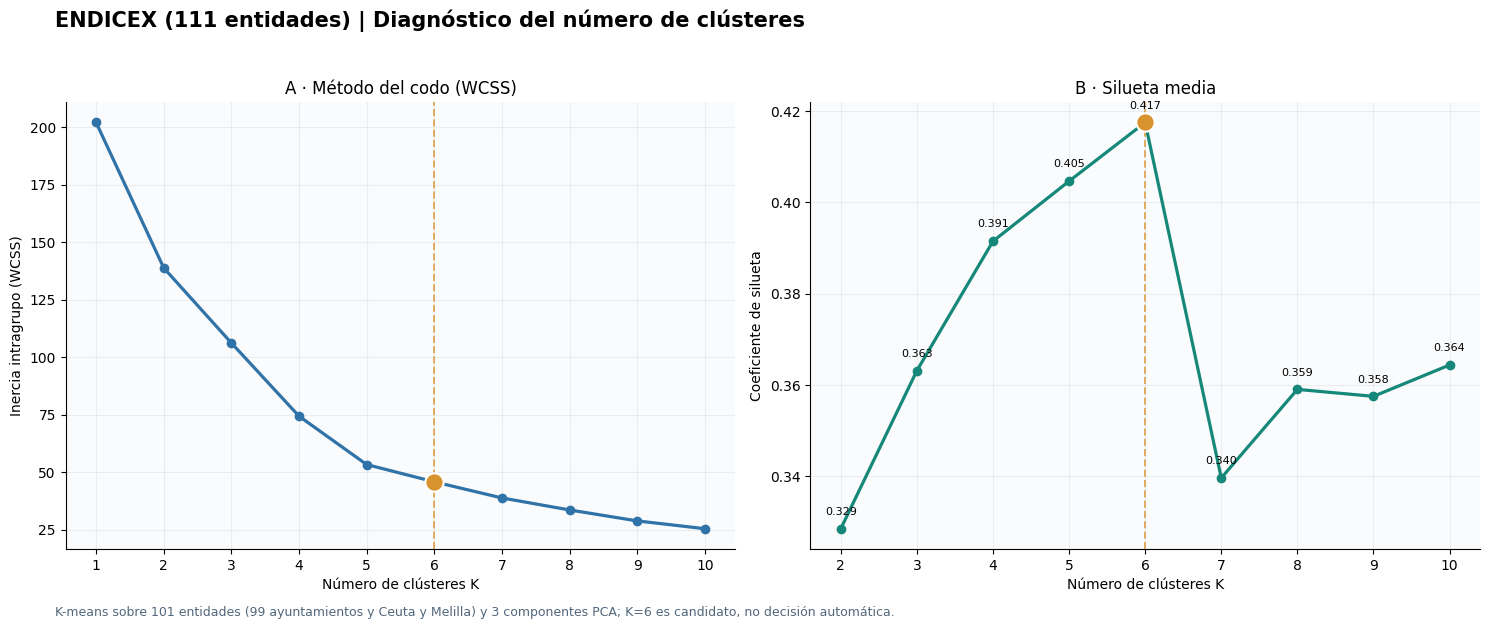


AYUNTAMIENTOS ANALIZADOS: 101

TABLA COMPLETA DE SELECCIÓN DE K:


,K,Inercia_WCSS,Silueta,Grupo_minimo,Grupo_maximo,Tamanos,Reduccion_WCSS_pct
0,1,202.000,NaN,101,101,101,NaN
1,2,138.784,0.329,50,51,51 / 50,31.295
2,3,106.179,0.363,4,49,49 / 48 / 4,23.494
3,4,74.361,0.391,4,47,47 / 46 / 4 / 4,29.966
4,5,53.341,0.405,4,48,48 / 32 / 13 / 4 / 4,28.268
5,6,45.821,0.417,2,47,47 / 31 / 13 / 4 / 4 / 2,14.097
6,7,38.818,0.340,2,31,31 / 29 / 19 / 12 / 4 / 4 / 2,15.283
7,8,33.606,0.359,2,31,31 / 29 / 19 / 10 / 4 / 3 / 3 / 2,13.428
8,9,28.846,0.358,1,30,30 / 29 / 20 / 10 / 3 / 3 / 3 / 2 / 1,14.165
9,10,25.457,0.364,1,30,30 / 29 / 20 / 6 / 4 / 3 / 3 / 3 / 2 / 1,11.748



MAYOR SILUETA: K=6 | 0.417
K=4: silueta=0.391; WCSS=74.36; grupo mínimo=4; tamaños=47 / 46 / 4 / 4
K=5: silueta=0.405; WCSS=53.34; grupo mínimo=4; tamaños=48 / 32 / 13 / 4 / 4
K=6: silueta=0.417; WCSS=45.82; grupo mínimo=2; tamaños=47 / 31 / 13 / 4 / 4 / 2

FIGURA GUARDADA: ENDICEX_111_Codo_y_Silueta.png
Diagnóstico exploratorio completado; comparar K=4, K=5 y K=6 antes de la selección definitiva.


In [11]:

### 4. Selección de K: método del codo y silueta
# Evaluación exploratoria del número de clústeres
# sobre las tres dimensiones de la matriz X.
# No se modifica X ni se fija todavía el K definitivo.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import display


### 4.1. Validación de la matriz X
# Se comprueban las tres dimensiones, la ausencia de
# valores no finitos y el tamaño mínimo de la muestra.

if 'X' not in globals():
    raise RuntimeError('Ejecuta primero las celdas de carga, PCA social y PCA financiero que generan X.')

X_diagnostico = np.asarray(X, dtype=float)

if X_diagnostico.ndim != 2 or X_diagnostico.shape[1] != 3:
    raise ValueError('La matriz X debe tener tres columnas: CP1 social y CP1–CP2 financieros.')

if not np.isfinite(X_diagnostico).all():
    raise ValueError('La matriz X tiene NaN o infinitos; revisa el PCA financiero.')

if len(X_diagnostico) < 12:
    raise ValueError('Se requieren al menos 12 municipios para comparar K de 2 a 10.')


### 4.2. Cálculo de inercia, silueta y tamaños
# Para cada K se calcula WCSS, silueta media y
# distribución de los tamaños de los conglomerados.
# K=1 solo permite calcular inercia.

K_CANDIDATO = 6
K_MAX = min(10, len(X_diagnostico) - 1)
SEMILLA = 42

filas = []
modelos_diagnostico = {}

for k in range(1, K_MAX + 1):
    modelo = KMeans(n_clusters=k, n_init=50, random_state=SEMILLA, max_iter=500)
    etiquetas = modelo.fit_predict(X_diagnostico)
    modelos_diagnostico[k] = modelo
    tamanos = np.bincount(etiquetas, minlength=k)
    sil = silhouette_score(X_diagnostico, etiquetas) if k >= 2 else np.nan

    filas.append({
        'K': k,
        'Inercia_WCSS': modelo.inertia_,
        'Silueta': sil,
        'Grupo_minimo': int(tamanos.min()),
        'Grupo_maximo': int(tamanos.max()),
        'Tamanos': ' / '.join(map(str, sorted(tamanos, reverse=True)))
    })

tabla_codo_silueta = pd.DataFrame(filas)

tabla_codo_silueta['Reduccion_WCSS_pct'] = (
    -100 * tabla_codo_silueta['Inercia_WCSS'].pct_change()
)


### 4.3. Representación gráfica de los criterios
# Gráfico A: evolución de la inercia WCSS.
# Gráfico B: coeficiente medio de silueta.

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.0, 5.8), facecolor='white')

ax1.plot(tabla_codo_silueta.K, tabla_codo_silueta.Inercia_WCSS,
         '-o', color='#3073A8', lw=2.3, markersize=6)

ax1.set(title='A · Método del codo (WCSS)', xlabel='Número de clústeres K',
        ylabel='Inercia intragrupo (WCSS)')
ax1.set_xticks(tabla_codo_silueta.K)

sub = tabla_codo_silueta.dropna(subset=['Silueta'])

ax2.plot(sub.K, sub.Silueta, '-o', color='#168879', lw=2.3, markersize=6)

ax2.set(title='B · Silueta media', xlabel='Número de clústeres K',
        ylabel='Coeficiente de silueta')
ax2.set_xticks(sub.K)

for _, reg in sub.iterrows():
    ax2.annotate(f'{reg.Silueta:.3f}', (reg.K,reg.Silueta),
                 xytext=(0, 10), textcoords='offset points', ha='center', fontsize=8)


### 4.4. Identificación visual del candidato exploratorio
# Se destaca K=6 únicamente como referencia visual.
# No se impone como número definitivo de clústeres.

if K_CANDIDATO <= K_MAX:
    ref = tabla_codo_silueta.loc[tabla_codo_silueta.K.eq(K_CANDIDATO)].iloc[0]

    for ax, dato in [(ax1, 'Inercia_WCSS'), (ax2, 'Silueta')]:
        ax.axvline(K_CANDIDATO, color='#D9932E', ls='--', lw=1.4, alpha=.75)
        ax.scatter([K_CANDIDATO], [ref[dato]], s=175, c='#D9932E',
                   edgecolor='white', linewidth=1.5, zorder=6)


### 4.5. Formato y exportación de la figura
# Se conserva el diseño original y se exporta en PNG.

for ax in (ax1,ax2):
    ax.set_facecolor('#FAFBFD')
    ax.grid(alpha=.20)
    ax.spines[['top','right']].set_visible(False)

fig.suptitle('ENDICEX (111 entidades) | Diagnóstico del número de clústeres',
             x=.04, y=1.03, ha='left', fontsize=15, weight='bold')

fig.text(.04, -.015,
         f'K-means sobre {len(X_diagnostico)} entidades (99 ayuntamientos y Ceuta y Melilla) y 3 componentes PCA; K=6 es candidato, no decisión automática.',
         fontsize=9, color='#52677C')

fig.tight_layout()

salida_diagnostico = 'ENDICEX_111_Codo_y_Silueta.png'

fig.savefig(salida_diagnostico, dpi=180, bbox_inches='tight', facecolor='white')
plt.show()


### 4.6. Presentación de resultados
# Tabla comparativa de K, silueta, inercia y tamaños.
# La mayor silueta no determina por sí sola el K final.

print(f'\nAYUNTAMIENTOS ANALIZADOS: {len(X_diagnostico)}')
print('\nTABLA COMPLETA DE SELECCIÓN DE K:')

display(tabla_codo_silueta.round(3))

mejor = sub.loc[sub.Silueta.idxmax()]

print(f'\nMAYOR SILUETA: K={int(mejor.K)} | {mejor.Silueta:.3f}')

for k in (4, 5, 6):
    fil = tabla_codo_silueta.loc[tabla_codo_silueta.K.eq(k)].iloc[0]
    print(f'K={k}: silueta={fil.Silueta:.3f}; '
          f'WCSS={fil.Inercia_WCSS:.2f}; grupo mínimo={int(fil.Grupo_minimo)}; '
          f'tamaños={fil.Tamanos}')

print(f'\nFIGURA GUARDADA: {salida_diagnostico}')
print('Diagnóstico exploratorio completado; comparar K=4, K=5 y K=6 antes de la selección definitiva.')



**Decisión metodológica sobre K óptimo**

El número de conglomerados se selecciona combinando dos criterios: **maximización del coeficiente de silueta** (Rousseeuw, 1987) y **tamaño mínimo de cuatro entidades por conglomerado**, con objeto de evitar agrupaciones excesivamente reducidas y favorecer su interpretabilidad.

Aunque **K=6 obtiene el mayor coeficiente de silueta (0,4175)**, esta solución no cumple el criterio de tamaño mínimo establecido.

Por tanto, se selecciona **K=5 (silueta = 0,4047)**, que satisface dicho requisito y presenta una reducción de apenas **0,0128 puntos** respecto de K=6.

La solución K=5 se adopta para el análisis multidimensional y la caracterización de los perfiles de fiscalización de las **101 entidades con información financiera válida**, incluidas Ceuta y Melilla.


# **5. Diagnósticos gráficos y caracterización de los conglomerados K1–K5**

Esta sección utiliza la solución K=5 seleccionada previamente para las 101 entidades con información financiera válida, incluidas Ceuta y Melilla. Las diez entidades sin cuentas de 2024 permanecen fuera de este análisis multidimensional.

Se visualizan la varianza explicada (5.2), las cargas de los PCA (5.3), las proyecciones 2D/3D (5.4), la silueta individual (5.5), los tamaños y la silueta por grupo (5.6), una tabla de comprobación de centroides (5.7), la relación entre grupos sociales S1–S3 y conglomerados K1–K5 mediante Sankey (5.8), un mapa de calor de los tres centroides PCA (5.9) y las huellas radar de vulnerabilidad económico-social, endeudamiento, gasto e inversión (5.10).
Identidad de los perfiles
Perfil	Color	Entidades	Caracterización exploratoria
K1	Azul	13	Baja vulnerabilidad social relativa
K2	Verde	48	Vulnerabilidad intermedia y baja singularidad financiera
K3	Amarillo	32	Vulnerabilidad elevada y singularidad financiera moderada
K4	Naranja	4	Singularidad financiera especialmente inversora
K5	Rojo	4	Vulnerabilidad elevada y singularidad vinculada al endeudamiento

Verificación K1–K5: {'K2': 48, 'K3': 32, 'K1': 13, 'K5': 4, 'K4': 4}
Muestra multivariante: 101 entidades; Ceuta y Melilla incluidas.


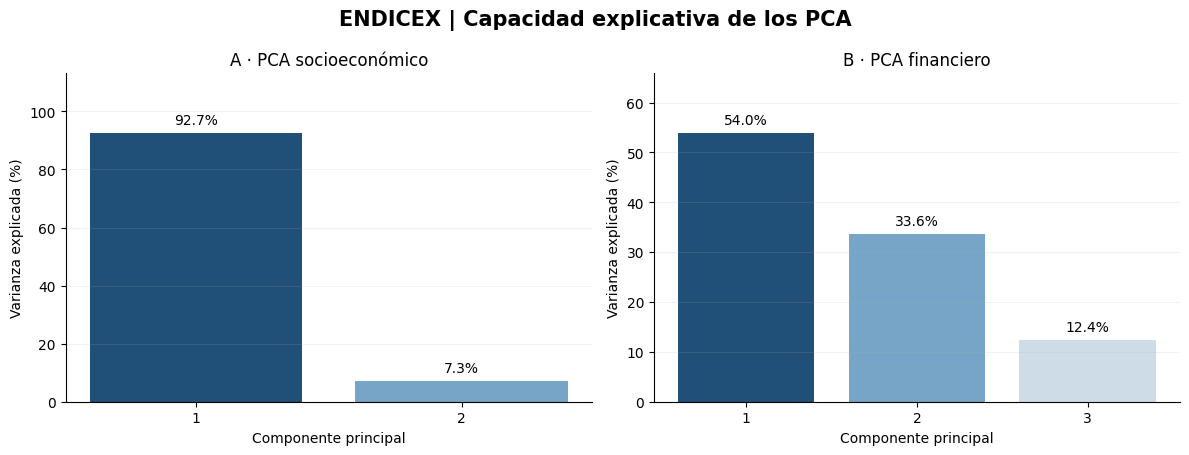

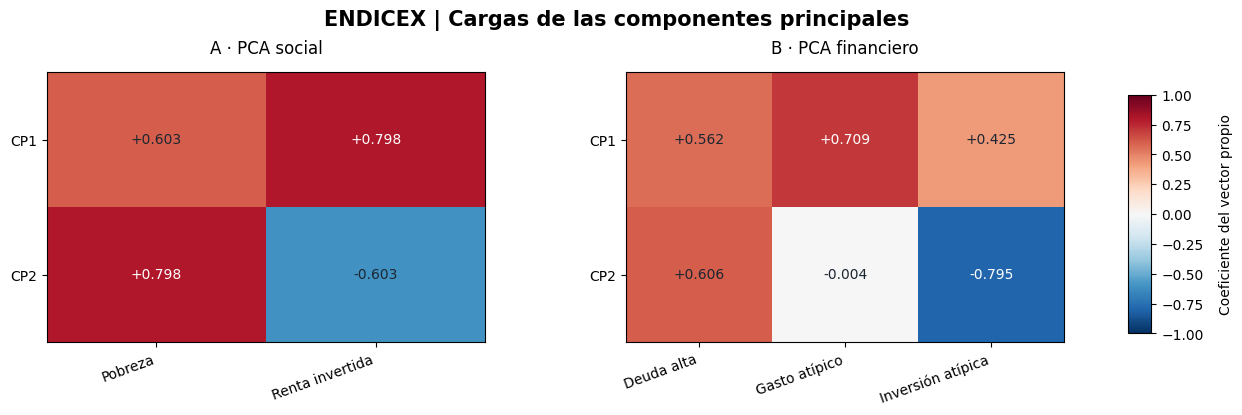

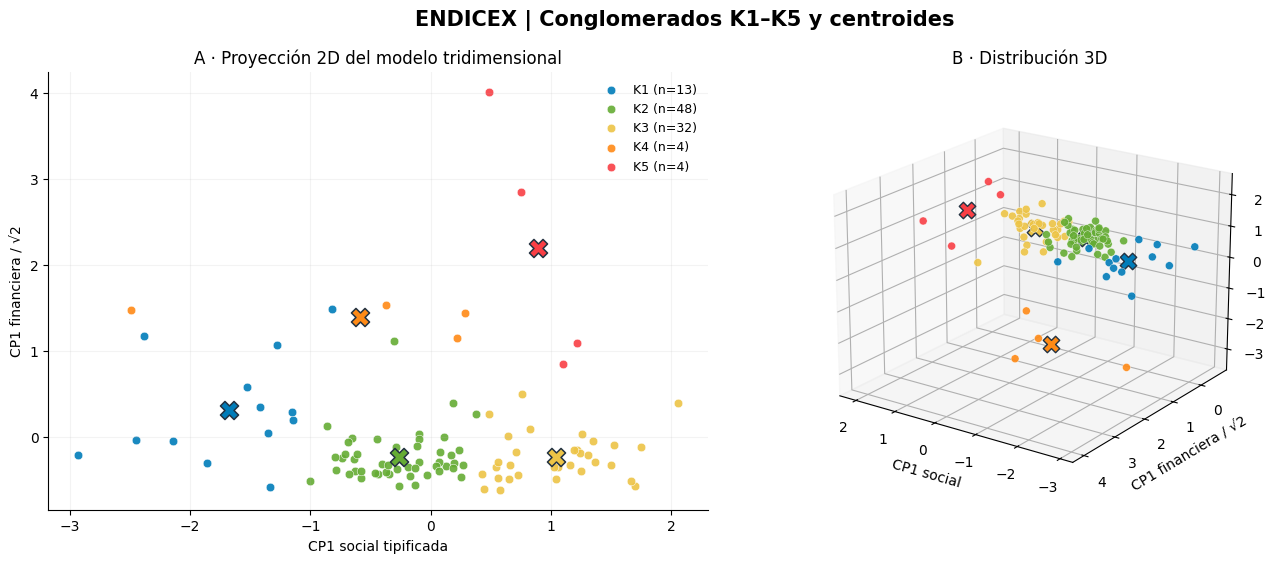

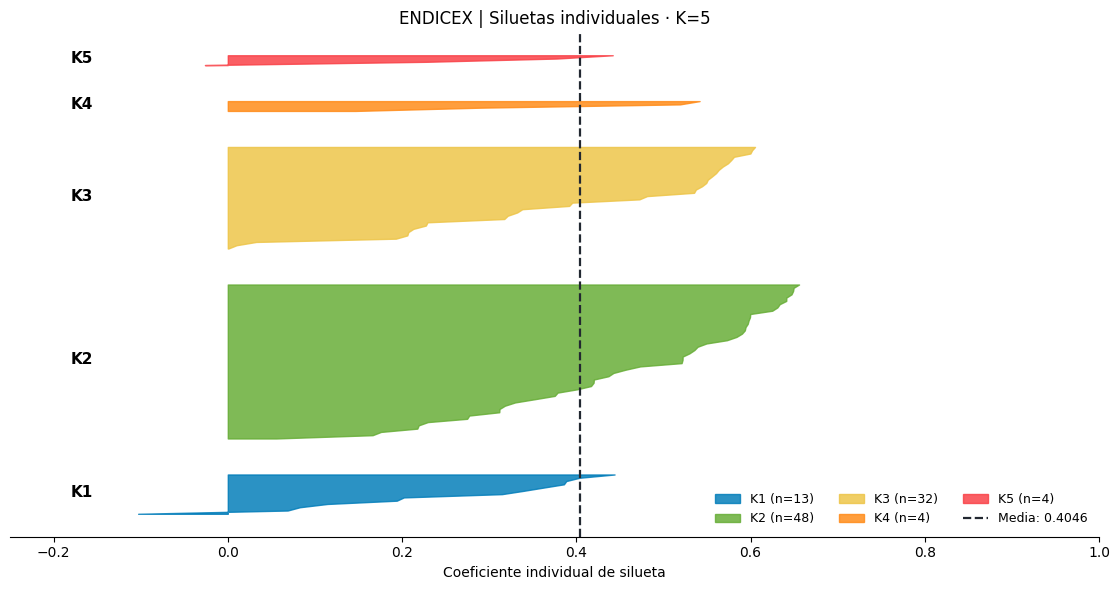

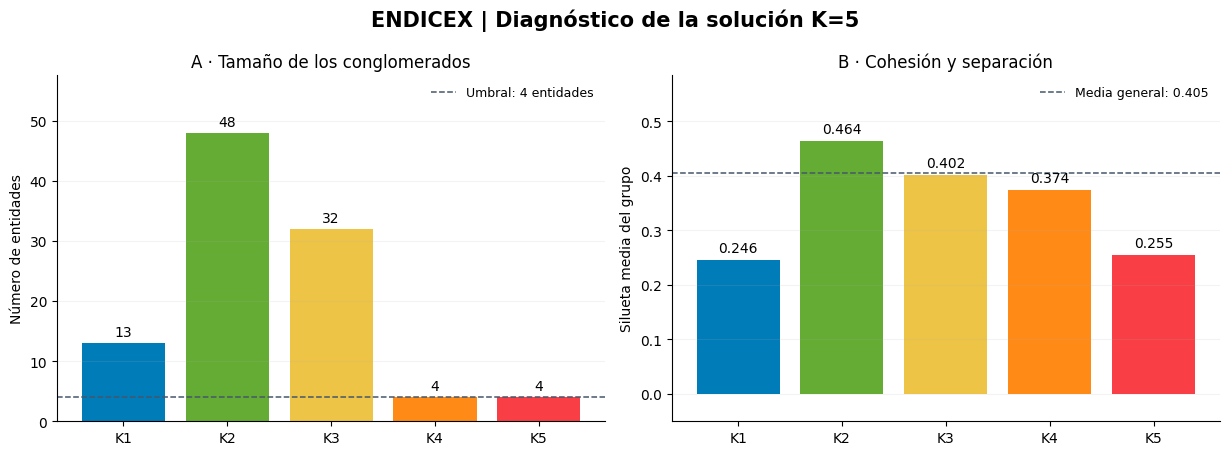

K=5 | n=101 | silueta=0.404630 | tamaño mínimo=4


,Grupo,N entidades,Silueta media,Centro social,Centro financiero CP1,Centro financiero CP2
0,K1,13,0.246,-1.676,0.312,-0.036
1,K2,48,0.464,-0.263,-0.232,0.061
2,K3,32,0.402,1.037,-0.231,0.027
3,K4,4,0.374,-0.590,1.403,-2.520
4,K5,4,0.255,0.890,2.204,1.688


cluster_K5,K1,K2,K3,K4,K5
cluster_social,,,,,
S1,12,0,0,1,0
S2,1,48,0,3,0
S3,0,0,32,0,4


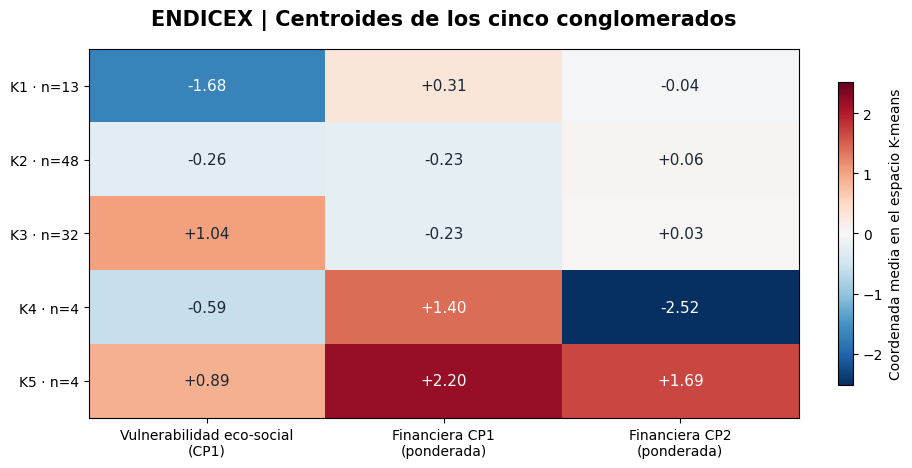

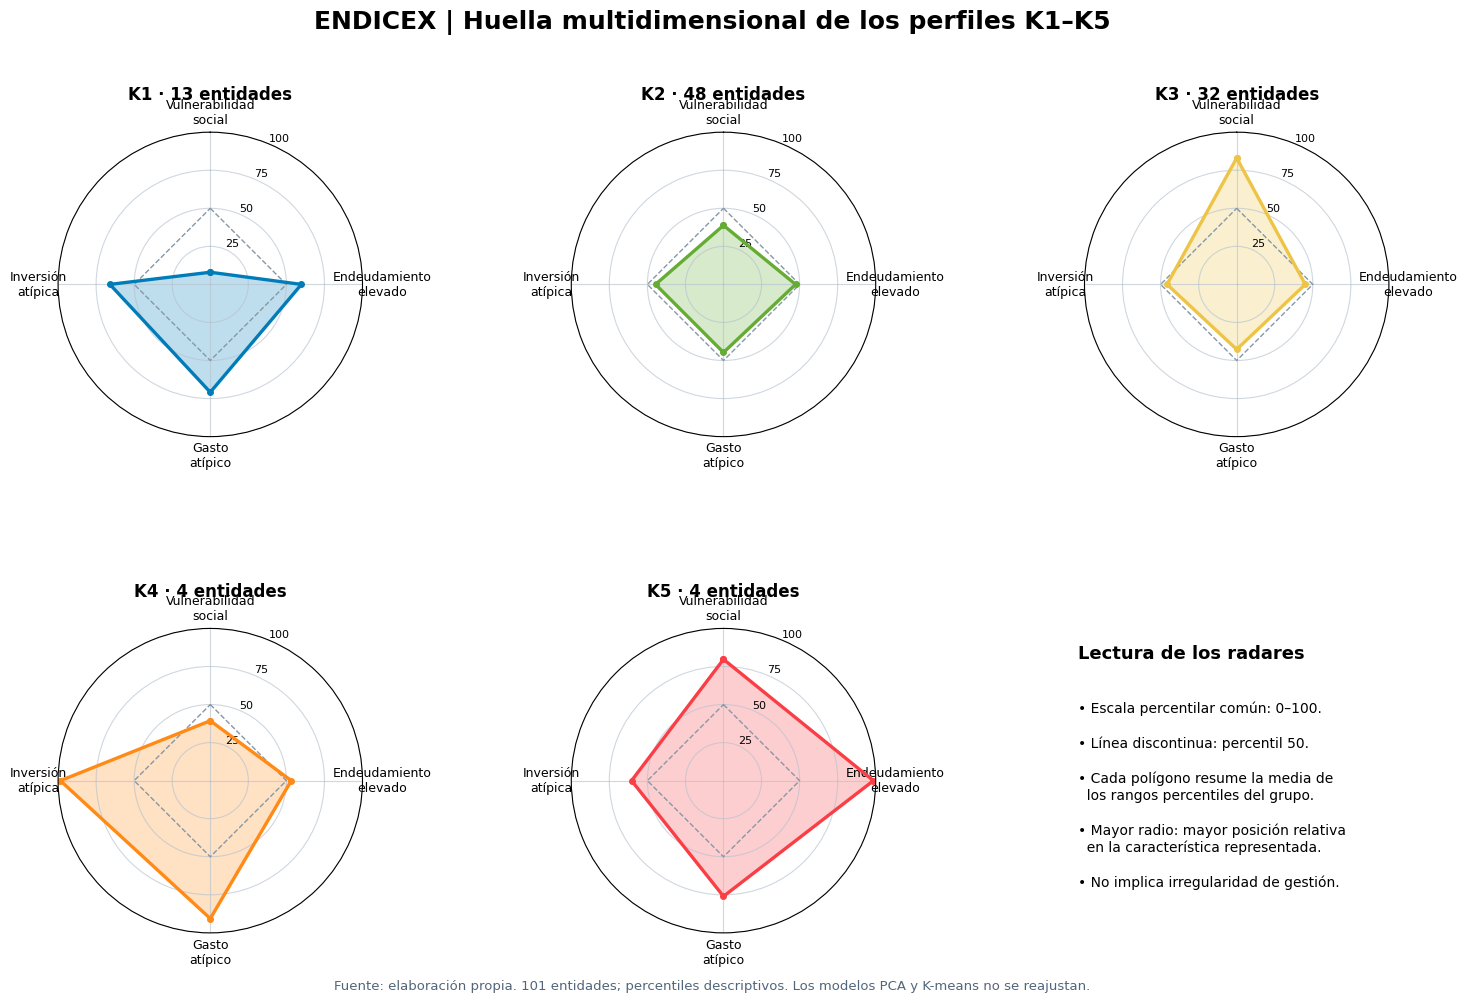

,Vulnerabilidad\nsocial,Endeudamiento\nelevado,Gasto\natípico,Inversión\natípica
Grupo,,,,
K1,8.00,59.86,70.83,65.96
K2,38.80,47.36,44.72,44.64
K3,83.04,45.05,42.70,45.76
K4,39.36,53.22,90.59,98.51
K5,79.70,98.51,75.99,60.40


Exportación finalizada: ENDICEX_Seccion5_Figuras_K1_K5.zip (11 archivos).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:

### 5. Diagnóstico y visualización de los conglomerados K1–K5
# Se verifican y representan los resultados del PCA y del K-means (K=5)
# de ENDICEX, sin recalcular los modelos ni modificar las asignaciones.
# Se analizan las 101 entidades clasificadas mediante:
# - Varianza explicada y cargas de las componentes principales.
# - Representaciones bidimensionales y tridimensionales de los conglomerados.
# - Coeficientes de silueta, tamaños y centroides de los cinco perfiles.
# - Diagrama Sankey, mapa de calor y gráficos radiales.
# Las figuras y tablas se guardan y exportan conjuntamente en un archivo ZIP.
# Los resultados son exploratorios y no constituyen hallazgos de fiscalización.


### 5.1. Verificación, etiquetas definitivas y paleta
# Identificación K1–K5 contrastada con la base auditada del artículo.
# La numeración de sklearn es arbitraria: el mapa se valida para este ajuste.

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_samples
import plotly.graph_objects as go
from IPython.display import display

requeridas = [
    'D', 'validos', 'X', 'X_diagnostico', 'modelos_diagnostico',
    'pca_social', 'pca_fin', 'social_rob', 'cp1_social',
    'cargas_fin', 'caract_fin', 'componentes_fin'
]
faltan = [v for v in requeridas if v not in globals()]
if faltan:
    raise RuntimeError('Ejecuta primero las secciones 1–4. Faltan: ' + ', '.join(faltan))

X_graf = np.asarray(X, dtype=float)
if X_graf.ndim != 2 or X_graf.shape[1] != 3 or not np.isfinite(X_graf).all():
    raise ValueError('X debe contener tres dimensiones finitas.')
if X_graf.shape != np.shape(X_diagnostico) or not np.allclose(X_graf, X_diagnostico):
    raise ValueError('X no coincide con la matriz utilizada para elegir K.')
if 5 not in modelos_diagnostico:
    raise ValueError('No se encuentra la solución K=5 de la sección 4.')

modelo5 = modelos_diagnostico[5]
etiquetas5 = np.asarray(modelo5.labels_, dtype=int)
datos_k5 = D.loc[validos].copy()
if len(etiquetas5) != len(X_graf) or len(datos_k5) != len(X_graf):
    raise ValueError('El orden o el número de entidades no coincide con las etiquetas K=5.')
if len(X_graf) != 101:
    raise ValueError(f'El análisis documentado comprende 101 entidades; X contiene {len(X_graf)}.')

# Equivalencia con K1–K5 del artículo, comprobada por código INE.
MAPA_K = {0: 'K1', 1: 'K3', 2: 'K2', 3: 'K5', 4: 'K4'}
PALETA_K = {
    'K1': '#007CB9',  # Azul
    'K2': '#65AC34',  # Verde
    'K3': '#EDC446',  # Amarillo
    'K4': '#FF8A16',  # Naranja
    'K5': '#F93F45',  # Rojo
}
ORDEN_K = ['K1', 'K2', 'K3', 'K4', 'K5']
GRUPOS = {k: next(i for i, v in MAPA_K.items() if v == k) for k in ORDEN_K}
COLORES = {i: PALETA_K[k] for i, k in MAPA_K.items()}

# Verificación de que la nomenclatura no se ha desplazado entre ejecuciones.
tamanos_reales = pd.Series([MAPA_K[i] for i in etiquetas5]).value_counts().to_dict()
tamanos_articulo = {'K1': 13, 'K2': 48, 'K3': 32, 'K4': 4, 'K5': 4}
if tamanos_reales != tamanos_articulo:
    raise ValueError('La correspondencia de grupos ha cambiado. Revisar MAPA_K antes de representar.')
if not (modelo5.cluster_centers_[GRUPOS['K4'], 2] < 0 < modelo5.cluster_centers_[GRUPOS['K5'], 2]):
    raise ValueError('La orientación de K4/K5 no coincide con la clasificación auditada.')

# Se añade una columna descriptiva. No se cambia ninguna clasificación.
datos_k5['cluster_K5'] = [MAPA_K[i] for i in etiquetas5]
D.loc[validos, 'cluster_K5'] = datos_k5['cluster_K5'].to_numpy()

CARPETA = Path('ENDICEX_Seccion5_Figuras')
CARPETA.mkdir(exist_ok=True)

def guardar(fig, nombre, ajustar=True):
    """Guardar PNG a 240 ppp, mostrarlo y cerrar su figura."""
    if ajustar:
        fig.tight_layout()
    ruta = CARPETA / f'ENDICEX_5_{nombre}.png'
    fig.savefig(ruta, dpi=240, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)
    return ruta

print('Verificación K1–K5:', tamanos_reales)
print('Muestra multivariante:', len(X_graf), 'entidades; Ceuta y Melilla incluidas.')


### 5.2. Varianza explicada por las componentes principales
# Se visualiza la varianza del PCA social y financiero ya ajustados.

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6), facecolor='white')
for ax, pca, titulo in [
    (ejes[0], pca_social, 'A · PCA socioeconómico'),
    (ejes[1], pca_fin, 'B · PCA financiero')
]:
    valores = 100 * pca.explained_variance_ratio_
    barras = ax.bar(np.arange(1, len(valores)+1), valores,
                    color=['#204F77', '#76A5C7', '#CEDCE8'][:len(valores)])
    ax.bar_label(barras, fmt='%.1f%%', padding=4, fontsize=10)
    ax.set(xlabel='Componente principal', ylabel='Varianza explicada (%)', title=titulo)
    ax.set_xticks(np.arange(1, len(valores)+1))
    ax.set_ylim(0, max(valores) * 1.22)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=.16)
fig.suptitle('ENDICEX | Capacidad explicativa de los PCA', fontsize=15, fontweight='bold')
guardar(fig, '2_Varianza_PCA')


### 5.3. Cargas de los PCA (vectores propios)
# Se recupera la orientación de CP1 social y se emplean cargas_fin ya orientadas.
# Las cargas no son correlaciones. La barra de color tiene espacio exclusivo.

social_raw = pca_social.transform(social_rob)[:, 0]
signo_social = -1 if np.corrcoef(social_raw, cp1_social)[0, 1] < 0 else 1
cargas_soc = pca_social.components_.copy()
cargas_soc[0] *= signo_social

fig, ejes = plt.subplots(1, 2, figsize=(12.8, 4.5), facecolor='white')
fig.subplots_adjust(left=.055, right=.85, bottom=.24, top=.84, wspace=.32)
for ax, matriz, columnas, titulo in [
    (ejes[0], cargas_soc, ['Pobreza', 'Renta invertida'], 'A · PCA social'),
    (ejes[1], cargas_fin[:2], ['Deuda alta', 'Gasto atípico', 'Inversión atípica'], 'B · PCA financiero')
]:
    im = ax.imshow(matriz, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(len(columnas)), columnas, rotation=20, ha='right')
    ax.set_yticks([0, 1], ['CP1', 'CP2'])
    ax.set_title(titulo, pad=14)
    for a, b in np.ndindex(matriz.shape):
        x = matriz[a, b]
        ax.text(b, a, f'{x:+.3f}', ha='center', va='center', fontsize=10,
                color='white' if abs(x) > .65 else '#1C2631')
cax = fig.add_axes([.90, .26, .018, .53])
cb = fig.colorbar(im, cax=cax)
cb.set_label('Coeficiente del vector propio', labelpad=11)
fig.suptitle('ENDICEX | Cargas de las componentes principales', fontsize=15, fontweight='bold')
guardar(fig, '3_Cargas_PCA', ajustar=False)


### 5.4. Proyección bidimensional y espacio tridimensional de K=5
# Coordenadas exactas de X y centros del K-means ajustado.
# La representación 2D omite una dimensión y no determina las asignaciones.

fig = plt.figure(figsize=(13.8, 5.7), facecolor='white')
ax2 = fig.add_subplot(121)
ax3 = fig.add_subplot(122, projection='3d')
for k in ORDEN_K:
    j = GRUPOS[k]
    sel = etiquetas5 == j
    color = PALETA_K[k]
    ax2.scatter(X_graf[sel, 0], X_graf[sel, 1], color=color, s=38,
                edgecolor='white', linewidth=.4, alpha=.90, label=f'{k} (n={sel.sum()})')
    ax3.scatter(X_graf[sel, 0], X_graf[sel, 1], X_graf[sel, 2],
                color=color, s=33, alpha=.90, edgecolor='white', linewidth=.3)
    centro = modelo5.cluster_centers_[j]
    ax2.scatter(*centro[:2], color=color, s=170, marker='X',
                edgecolor='#233241', linewidth=1.1, zorder=10)
    ax3.scatter(*centro, color=color, s=140, marker='X',
                edgecolor='#233241', linewidth=1.0, depthshade=False)
ax2.set(xlabel='CP1 social tipificada', ylabel='CP1 financiera / √2',
        title='A · Proyección 2D del modelo tridimensional')
ax2.grid(alpha=.15)
ax2.spines[['top', 'right']].set_visible(False)
ax2.legend(frameon=False, fontsize=9, loc='best')
ax3.set(xlabel='CP1 social', ylabel='CP1 financiera / √2',
        zlabel='CP2 financiera / √2', title='B · Distribución 3D')
ax3.view_init(elev=20, azim=125)
fig.suptitle('ENDICEX | Conglomerados K1–K5 y centroides', fontsize=15, fontweight='bold')
guardar(fig, '4_Clusters_2D_3D')


### 5.5. Silueta individual de los cinco conglomerados
# Se calcula la silueta descriptiva sobre X; NO se reentrena K-means.

siluetas_individuales = silhouette_samples(X_graf, etiquetas5)
silueta_media = float(siluetas_individuales.mean())
fig, ax = plt.subplots(figsize=(11.3, 6.0), facecolor='white')
y_actual = 10
for k in ORDEN_K:
    j = GRUPOS[k]
    valores = np.sort(siluetas_individuales[etiquetas5 == j])
    y_fin = y_actual + len(valores)
    ax.fill_betweenx(np.arange(y_actual, y_fin), 0, valores,
                     color=PALETA_K[k], alpha=.83, label=f'{k} (n={len(valores)})')
    ax.text(min(-.18, siluetas_individuales.min()-.04), (y_actual+y_fin)/2,
            k, va='center', fontsize=11, fontweight='bold')
    y_actual = y_fin + 10
ax.axvline(silueta_media, color='#222831', ls='--', lw=1.6,
           label=f'Media: {silueta_media:.4f}')
ax.set(xlim=(min(-.25, siluetas_individuales.min()-.10), 1.0),
       yticks=[], xlabel='Coeficiente individual de silueta',
       title='ENDICEX | Siluetas individuales · K=5')
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.legend(ncol=3, fontsize=9, frameon=False, loc='lower right')
guardar(fig, '5_Siluetas_K5')


### 5.6. Tamaños de los conglomerados y cohesión media
# Control explícito del mínimo de cuatro entidades por conglomerado.

recuento = np.array([np.sum(etiquetas5 == GRUPOS[k]) for k in ORDEN_K])
media_silueta = np.array([
    siluetas_individuales[etiquetas5 == GRUPOS[k]].mean() for k in ORDEN_K
])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.4, 4.6), facecolor='white')
barra = ax1.bar(ORDEN_K, recuento, color=[PALETA_K[k] for k in ORDEN_K])
ax1.bar_label(barra, padding=3)
ax1.axhline(4, ls='--', color='#45566A', lw=1.1, label='Umbral: 4 entidades')
ax1.set(ylabel='Número de entidades', title='A · Tamaño de los conglomerados',
        ylim=(0, recuento.max() * 1.2))
ax1.legend(frameon=False, fontsize=9)
barra2 = ax2.bar(ORDEN_K, media_silueta, color=[PALETA_K[k] for k in ORDEN_K])
ax2.bar_label(barra2, fmt='%.3f', padding=3)
ax2.axhline(silueta_media, ls='--', color='#45566A', lw=1.1,
            label=f'Media general: {silueta_media:.3f}')
ax2.set(ylabel='Silueta media del grupo', title='B · Cohesión y separación',
        ylim=(min(-.05, min(media_silueta)-.08), max(.12, max(media_silueta)+.12)))
ax2.legend(frameon=False, fontsize=9)
for ax in (ax1, ax2):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', alpha=.15)
fig.suptitle('ENDICEX | Diagnóstico de la solución K=5', fontsize=15, fontweight='bold')
guardar(fig, '6_Tamanos_y_Siluetas')


### 5.7. Tabla de perfiles y control metodológico
# Los centroides son coordenadas de X, no unidades monetarias ni porcentajes.

resumen_K5 = pd.DataFrame({
    'Grupo': ORDEN_K,
    'N entidades': recuento,
    'Silueta media': media_silueta,
    'Centro social': [modelo5.cluster_centers_[GRUPOS[k], 0] for k in ORDEN_K],
    'Centro financiero CP1': [modelo5.cluster_centers_[GRUPOS[k], 1] for k in ORDEN_K],
    'Centro financiero CP2': [modelo5.cluster_centers_[GRUPOS[k], 2] for k in ORDEN_K]
})
if recuento.min() < 4:
    raise ValueError('K=5 no satisface el mínimo de cuatro entidades.')
print(f'K=5 | n={len(X_graf)} | silueta={silueta_media:.6f} | tamaño mínimo={recuento.min()}')
display(resumen_K5.round(3))
resumen_K5.to_csv(CARPETA/'ENDICEX_5_7_Resumen_K5.csv', index=False, encoding='utf-8-sig')


### 5.8. Sankey: grupos sociales S1–S3 y conglomerados K1–K5
# Corresponde a la misma población del K-means. No se recalcula el PCA social.

if 'cluster_social' not in datos_k5.columns:
    raise ValueError('Falta la clasificación social auxiliar S1–S3.')
sociales = ['S1', 'S2', 'S3']
tabla_flujos = pd.crosstab(datos_k5['cluster_social'], datos_k5['cluster_K5']).reindex(
    index=sociales, columns=ORDEN_K, fill_value=0
)
if tabla_flujos.to_numpy().sum() != len(X_graf):
    raise ValueError('El cruce S1–S3 × K1–K5 no incluye las 101 entidades.')
display(tabla_flujos)
tabla_flujos.to_csv(CARPETA/'ENDICEX_5_8_Transiciones_Social_K5.csv', encoding='utf-8-sig')

col_social = ['#A7C7DA', '#5B92B1', '#25577C']
fuente, destino, valor, flujo_color, texto_flujo = [], [], [], [], []
for i, social in enumerate(sociales):
    for j, k in enumerate(ORDEN_K):
        n = int(tabla_flujos.loc[social, k])
        if n:
            fuente.append(i)
            destino.append(3+j)
            valor.append(n)
            rgb = tuple(int(PALETA_K[k][a:a+2], 16) for a in (1, 3, 5))
            flujo_color.append(f'rgba({rgb[0]},{rgb[1]},{rgb[2]},0.34)')
            texto_flujo.append(f'{social} → {k}')

nodos = [f'{s} (n={tabla_flujos.loc[s].sum()})' for s in sociales] + [
    f'{k} (n={tabla_flujos[k].sum()})' for k in ORDEN_K
]
fig_sankey = go.Figure(go.Sankey(
    arrangement='snap',
    node=dict(label=nodos, color=col_social+[PALETA_K[k] for k in ORDEN_K],
              pad=24, thickness=22, line=dict(color='white', width=1)),
    link=dict(source=fuente, target=destino, value=valor, color=flujo_color,
              customdata=texto_flujo,
              hovertemplate='%{customdata}: %{value} entidades<extra></extra>')
))
fig_sankey.update_layout(
    title=dict(text='ENDICEX | De los grupos sociales a los perfiles K1–K5', x=.04),
    template='plotly_white', font=dict(size=13), height=630,
    margin=dict(l=45, r=45, t=105, b=60)
)
if 'google.colab' in sys.modules or 'ipykernel' in sys.modules:
    fig_sankey.show()
fig_sankey.write_html(CARPETA/'ENDICEX_5_8_Sankey.html', include_plotlyjs=True)


### 5.9. Mapa de calor de centroides: tres coordenadas de X
# No se incorporan Gini ni rendición de cuentas porque NO son ejes del K-means.

matriz_centros = np.vstack([modelo5.cluster_centers_[GRUPOS[k]] for k in ORDEN_K])
limite = max(.1, float(np.max(np.abs(matriz_centros))))
fig, ax = plt.subplots(figsize=(10.6, 5.2), facecolor='white')
im = ax.imshow(matriz_centros, cmap='RdBu_r', vmin=-limite, vmax=limite,
               aspect='auto')
ax.set_xticks(range(3), ['Vulnerabilidad eco-social\n(CP1)',
                         'Financiera CP1\n(ponderada)',
                         'Financiera CP2\n(ponderada)'])
ax.set_yticks(range(5), [f'{k} · n={tamanos_reales[k]}' for k in ORDEN_K])
ax.set_title('ENDICEX | Centroides de los cinco conglomerados',
             fontsize=15, fontweight='bold', pad=17)
for i, j in np.ndindex(matriz_centros.shape):
    v = matriz_centros[i, j]
    ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=11,
            color='white' if abs(v) > .55*limite else '#1B2735')
cb = fig.colorbar(im, ax=ax, shrink=.82, pad=.05, fraction=.045)
cb.set_label('Coordenada media en el espacio K-means')
fig.subplots_adjust(left=.17, right=.91, bottom=.17, top=.88)
guardar(fig, '9_Centroides_K5', ajustar=False)


### 5.10. Cinco radares: huella social y financiera de cada perfil
# Cuatro dimensiones interpretables. El rango percentil SOLO se usa para dibujar.
# Cada radar muestra la MEDIA de los percentiles individuales de su grupo.

if len(caract_fin) != len(X_graf):
    raise ValueError('Las características financieras no corresponden a X.')
dimensiones = [
    'Vulnerabilidad\nsocial', 'Endeudamiento\nelevado',
    'Gasto\natípico', 'Inversión\natípica'
]
valores_base = np.column_stack([
    datos_k5['CP1_social'].to_numpy(dtype=float),
    np.asarray(caract_fin, dtype=float)
])
if not np.isfinite(valores_base).all():
    raise ValueError('Existen valores no finitos en las características de los radares.')
percentiles = pd.DataFrame(valores_base, columns=dimensiones).rank(
    method='average', pct=True
) * 100
percentiles['Grupo'] = [MAPA_K[j] for j in etiquetas5]
perfil_radar = percentiles.groupby('Grupo')[dimensiones].mean().reindex(ORDEN_K)
perfil_radar.to_csv(CARPETA/'ENDICEX_5_10_Huellas_Percentiles.csv', encoding='utf-8-sig')

angulos = np.linspace(0, 2*np.pi, 4, endpoint=False)
angulos_cerrados = np.r_[angulos, angulos[0]]
fig = plt.figure(figsize=(15.0, 10.2), facecolor='white')
fig.suptitle('ENDICEX | Huella multidimensional de los perfiles K1–K5',
             fontsize=18, fontweight='bold', y=.985)
for i, k in enumerate(ORDEN_K):
    ax = fig.add_subplot(2, 3, i+1, projection='polar')
    perfil = perfil_radar.loc[k].to_numpy(dtype=float)
    ax.set_theta_offset(np.pi/2)
    ax.set_theta_direction(-1)
    ax.set_thetagrids(np.degrees(angulos), dimensiones, fontsize=9)
    ax.set_ylim(0, 100)
    ax.set_yticks([25, 50, 75, 100], ['25', '50', '75', '100'])
    ax.tick_params(axis='y', labelsize=8)
    ax.set_rlabel_position(22.5)
    ax.grid(color='#B5C1CE', alpha=.64)
    ax.plot(angulos_cerrados, [50]*5, color='#8697A5', ls='--', lw=1.0)
    ax.plot(angulos_cerrados, np.r_[perfil, perfil[0]],
            color=PALETA_K[k], lw=2.4, marker='o', markersize=4)
    ax.fill(angulos_cerrados, np.r_[perfil, perfil[0]],
            color=PALETA_K[k], alpha=.25)
    ax.set_title(f'{k} · {tamanos_reales[k]} entidades',
                 fontsize=12, fontweight='bold', pad=23)

ax_nota = fig.add_subplot(2, 3, 6)
ax_nota.axis('off')
ax_nota.text(.02, .90, 'Lectura de los radares',
             fontsize=13, fontweight='bold', transform=ax_nota.transAxes)
ax_nota.text(.02, .76,
             '• Escala percentilar común: 0–100.\n\n'
             '• Línea discontinua: percentil 50.\n\n'
             '• Cada polígono resume la media de\n'
             '  los rangos percentiles del grupo.\n\n'
             '• Mayor radio: mayor posición relativa\n'
             '  en la característica representada.\n\n'
             '• No implica irregularidad de gestión.',
             fontsize=10, va='top', linespacing=1.28,
             transform=ax_nota.transAxes)
fig.subplots_adjust(left=.055, right=.96, top=.865, bottom=.08,
                    wspace=.55, hspace=.63)
fig.text(.5, .024,
         'Fuente: elaboración propia. 101 entidades; percentiles descriptivos. '
         'Los modelos PCA y K-means no se reajustan.',
         ha='center', fontsize=9.5, color='#52657A')
guardar(fig, '10_Huella_Radares_K5', ajustar=False)
display(perfil_radar.round(2))


### 5.11. Exportación conjunta de figuras y tablas
# Se guarda un ZIP para descargar todas las figuras de la sección de una vez.

zip_salida = 'ENDICEX_Seccion5_Figuras_K1_K5.zip'
with ZipFile(zip_salida, 'w', compression=ZIP_DEFLATED) as paquete:
    for ruta in sorted(CARPETA.iterdir()):
        if ruta.is_file():
            paquete.write(ruta, arcname=ruta.name)

print(f'Exportación finalizada: {zip_salida} ({len(list(CARPETA.iterdir()))} archivos).')
try:
    from google.colab import files
    files.download(zip_salida)
except ImportError:
    pass


In [31]:
### 6. Consolidación y exportación de resultados
# Se integran y validan los resultados del PCA y K-means (K=5), sin recalcular los modelos.
# Se genera ENDICEX_Resultados_PCA_Kmeans_K5.xlsx con cuatro hojas:
# - Resumen: caracterización de los conglomerados K1–K5.
# - 101_municipios: resultados de las 101 entidades clasificadas.
# - Base_111: información y resultados de las 111 entidades.
# - Metodologia: criterios metodológicos, controles y paleta de colores.
# Los resultados son exploratorios y no constituyen hallazgos de fiscalización.

### 6.0. Dependencias y resultados previos
from pathlib import Path
import numpy as np
import pandas as pd
from google.colab import files

try:
    import xlsxwriter  # noqa: F401
except ModuleNotFoundError as exc:
    raise RuntimeError(
        'Falta XlsxWriter. Instálalo previamente con: '
        'python -m pip install XlsxWriter'
    ) from exc

NECESARIAS = ['D', 'validos', 'X', 'modelos_diagnostico', 'MAPA_K', 'PALETA_K']
faltan_variables = [v for v in NECESARIAS if v not in globals()]
if faltan_variables:
    raise RuntimeError(
        'Ejecuta primero los apartados 1–5; faltan: '
        + ', '.join(faltan_variables)
    )

if 'base_salida' in globals():
    origen_publicacion = base_salida.copy()
elif 'base_pca' in globals():
    origen_publicacion = base_pca.copy()
else:
    raise RuntimeError(
        'Falta base_salida o base_pca. Ejecuta antes el anexo '
        'que prepara las 111 entidades y las componentes individuales.'
    )


### 6.1. Consolidación de la base para publicación
COLUMNAS_PUBLICAS = [
    'numero', 'codigo_ine', 'id_aleatorio', 'provincia', 'comunidad',
    'tipo_entidad', 'poblacion', 'estrato',
    'GASTO MUNICIPAL', 'GTO HAB', 'END HAB', 'INV POR HAB',
    'falta rendición', 'cuentas 24', 'Cuentas 23',
    'inclusion_forzosa', 'requiere_fuente_institucional_especifica',
    'renta_media_persona', 'gini', 'pobreza_total_60',
    'Estado de rendición', 'Incidencia en rendición',
    'Participa en clustering 3D',
    'PC1 social (bruto)', 'PC1 social tipificado',
    'Alerta deuda alta (IQR)', 'Atipicidad gasto (IQR)',
    'Atipicidad inversion (IQR)',
    'PC1 financiero (bruto)', 'PC2 financiero (bruto)',
    'PC1 financiero ponderado', 'PC2 financiero ponderado',
    'Cluster K-means K5', 'Distancia euclidea centroide 3D',
    'Silueta individual K5', 'Situacion analitica',
]

if len(COLUMNAS_PUBLICAS) != 36 or len(set(COLUMNAS_PUBLICAS)) != 36:
    raise ValueError('La estructura pública debe tener 36 columnas únicas.')

campos_faltantes = [c for c in COLUMNAS_PUBLICAS if c not in origen_publicacion]
if campos_faltantes:
    raise ValueError(
        'Faltan columnas ya calculadas en la base de origen: '
        + ', '.join(campos_faltantes)
    )

base_salida = origen_publicacion.loc[:, COLUMNAS_PUBLICAS].copy()


def normalizar_ine(serie):
    """Conservar los cinco dígitos y los ceros iniciales del código INE."""
    codigos = (
        serie.astype('string').str.strip()
        .str.replace(r'\.0$', '', regex=True).str.zfill(5)
    )
    if codigos.isna().any() or not codigos.str.fullmatch(r'\d{5}').all():
        raise ValueError('Hay códigos INE nulos o con formato no válido.')
    return codigos.astype(str)


base_salida['codigo_ine'] = normalizar_ine(base_salida['codigo_ine'])
codigos_D = normalizar_ine(D['codigo_ine'])

if len(base_salida) != 111 or base_salida['codigo_ine'].nunique() != 111:
    raise ValueError('Base_111 debe contener 111 códigos INE únicos.')
if codigos_D.nunique() != 111 or set(codigos_D) != set(base_salida['codigo_ine']):
    raise ValueError('Los códigos INE del resultado y de D no coinciden.')


### 6.2. Clasificación definitiva K1–K5 por código INE
modelo5 = modelos_diagnostico[5]
etiquetas = np.asarray(modelo5.labels_, dtype=int)
X_3D = np.asarray(X, dtype=float)
mascara = np.asarray(validos, dtype=bool)

if len(mascara) != len(D) or len(etiquetas) != 101 or X_3D.shape != (101, 3):
    raise ValueError('Se esperan 111 observaciones, 101 etiquetas y X de 101×3.')
if not np.isfinite(X_3D).all():
    raise ValueError('La matriz X contiene valores no finitos.')
if set(np.unique(etiquetas)) != set(MAPA_K):
    raise ValueError('MAPA_K no cubre las cinco etiquetas internas.')

codigos_101_D = codigos_D.loc[D.index[validos]]
if codigos_101_D.duplicated().any():
    raise ValueError('Existen códigos INE duplicados entre las 101 entidades.')

clasificacion_ine = pd.Series(
    [MAPA_K[int(j)] for j in etiquetas],
    index=codigos_101_D.to_numpy(),
    name='Cluster K-means K5',
)

if 'cluster_K5' in D.columns:
    if not np.array_equal(
        D.loc[validos, 'cluster_K5'].to_numpy(),
        clasificacion_ine.to_numpy(),
    ):
        raise ValueError('Los perfiles no coinciden con el apartado 5.')

TAMANOS_K = {'K1': 13, 'K2': 48, 'K3': 32, 'K4': 4, 'K5': 4}
if clasificacion_ine.value_counts().to_dict() != TAMANOS_K:
    raise ValueError('La distribución K1–K5 difiere de la solución auditada.')
if set(PALETA_K) != set(TAMANOS_K):
    raise ValueError('La paleta K1–K5 está incompleta.')

base_salida['Cluster K-means K5'] = (
    base_salida['codigo_ine'].map(clasificacion_ine).astype(object)
)
mask_publica = base_salida['Cluster K-means K5'].notna()
if int(mask_publica.sum()) != 101:
    raise ValueError('El cruce por código INE no ha identificado 101 entidades.')

coordenadas_por_ine = pd.DataFrame(
    X_3D,
    index=codigos_101_D.to_numpy(),
    columns=[
        'PC1 social tipificado',
        'PC1 financiero ponderado',
        'PC2 financiero ponderado',
    ],
)
comparacion = (
    base_salida.loc[mask_publica, ['codigo_ine'] + list(coordenadas_por_ine.columns)]
    .set_index('codigo_ine').loc[coordenadas_por_ine.index]
)
if not np.allclose(
    comparacion.to_numpy(dtype=float),
    coordenadas_por_ine.to_numpy(dtype=float),
    rtol=1e-9, atol=1e-9,
):
    raise ValueError('Las coordenadas PCA exportadas difieren de X.')

base_salida['Situacion analitica'] = np.where(
    mask_publica, 'Clasificada en K-means (K=5)', 'No participa en K-means'
)


### 6.3. Resumen descriptivo de los cinco conglomerados
entidades_101 = base_salida.loc[mask_publica, COLUMNAS_PUBLICAS].copy()

resumen = (
    entidades_101.groupby('Cluster K-means K5', as_index=False)
    .agg(
        Entidades=('codigo_ine', 'size'),
        Silueta_media=('Silueta individual K5', 'mean'),
        Distancia_media_centroide=('Distancia euclidea centroide 3D', 'mean'),
        PC1_social_medio=('PC1 social tipificado', 'mean'),
        PC1_financiero_medio=('PC1 financiero ponderado', 'mean'),
        PC2_financiero_medio=('PC2 financiero ponderado', 'mean'),
    )
    .sort_values('Cluster K-means K5')
    .reset_index(drop=True)
)


### 6.4. Controles de integridad finales
if base_salida.shape != (111, 36) or entidades_101.shape != (101, 36):
    raise ValueError(
        f'Dimensiones inesperadas: {base_salida.shape}, {entidades_101.shape}.'
    )
if list(base_salida.columns) != list(entidades_101.columns):
    raise ValueError('Las columnas de las dos hojas deben coincidir.')
if entidades_101['Cluster K-means K5'].value_counts().to_dict() != TAMANOS_K:
    raise ValueError('Los tamaños de K1–K5 no coinciden con los esperados.')
if base_salida.loc[~mask_publica, 'PC1 financiero ponderado'].notna().any():
    raise ValueError('Hay componentes financieras en entidades no clasificadas.')
if not (entidades_101['Cluster K-means K5'].notna().all()):
    raise ValueError('Hay entidades seleccionadas sin clúster.')
if int(resumen['Entidades'].sum()) != 101:
    raise ValueError('El resumen no incluye las 101 entidades clasificadas.')

faltan_seleccion = [
    c for c in ('inclusion_forzosa', 'requiere_fuente_institucional_especifica')
    if c not in D.columns or D[c].isna().all()
]
if faltan_seleccion:
    print('AVISO: campos de selección sin datos de origen:', faltan_seleccion)


### 6.5. Metodología y paleta cromática
metodologia_filas = [
    ('Fuente', 'Muestra_111 seudonimizada, con END HAB imputado.'),
    ('Muestra inicial', 111),
    ('Entidades clasificadas', 101),
    ('No clasificadas', 10),
    ('Método', 'PCA social + PCA financiero + K-means, K=5.'),
    ('PCA social', 'Pobreza total y renta invertida; tipificación robusta mediana/IQR.'),
    ('Ingeniería financiera', 'Deuda elevada y desviaciones absolutas de gasto e inversión (IQR).'),
    ('Geometría K-means', 'PC1 social tipificada; PC1 y PC2 financieras estandarizadas / √2.'),
    ('Selección de K', 'K=5 con tamaño mínimo de cuatro entidades por conglomerado.'),
    ('Identificación de perfiles', 'Etiquetas finales K1–K5, correspondientes al artículo ENDICEX.'),
    ('Centroides y distancias', 'Medias y distancias euclídeas en el espacio tridimensional X.'),
    ('Silueta', 'Coeficiente de silueta individual calculado sobre X y etiquetas K=5.'),
    ('Paleta', 'Se utilizan los mismos colores HEX que en el apartado 5.'),
]
for k in ('K1', 'K2', 'K3', 'K4', 'K5'):
    metodologia_filas.append((f'Paleta {k}', PALETA_K[k]))
metodologia_filas.extend([
    ('Identificación', 'Código INE e id_aleatorio; sin nombres de municipios.'),
    ('Campos sin fuente', ', '.join(faltan_seleccion) if faltan_seleccion else 'Ninguno.'),
    ('Alcance', 'Análisis exploratorio; no constituye hallazgo de fiscalización.'),
])
metodologia = pd.DataFrame(metodologia_filas, columns=['Elemento', 'Descripción'])


### 6.6. Exportación del Excel con cuatro hojas
SALIDA = Path('ENDICEX_Resultados_PCA_Kmeans_K5.xlsx')
hojas = [
    ('Resumen', resumen, 'ENDICEX · PERFILES MULTIVARIANTES K1–K5'),
    ('101_municipios', entidades_101, '101 ENTIDADES · COMPONENTES Y PERFILES K1–K5'),
    ('Base_111', base_salida, 'BASE DE 111 ENTIDADES · RESULTADOS PCA Y K-MEANS'),
    ('Metodologia', metodologia, 'ENDICEX · METODOLOGÍA Y PALETA K1–K5'),
]

with pd.ExcelWriter(SALIDA, engine='xlsxwriter') as writer:
    libro_writer = writer.book
    formato_titulo = libro_writer.add_format({
        'bold': True, 'font_size': 15, 'font_color': '#14334A',
    })
    formato_cab = libro_writer.add_format({
        'bold': True, 'bg_color': '#14334A', 'font_color': '#FFFFFF',
        'text_wrap': True, 'valign': 'vcenter',
    })
    formato_nota = libro_writer.add_format({'italic': True, 'font_color': '#53687A'})
    formatos_k = {
        k: libro_writer.add_format({
            'bg_color': hex_,
            'bold': True,
            'font_color': '#1F2937' if k in ('K2', 'K3', 'K4') else '#FFFFFF',
        })
        for k, hex_ in PALETA_K.items()
    }

    for nombre, tabla, titulo in hojas:
        tabla.to_excel(writer, sheet_name=nombre, index=False, startrow=3)
        sh = writer.sheets[nombre]
        sh.write(0, 0, titulo, formato_titulo)
        sh.write(1, 0, 'Resultados seudonimizados de carácter exploratorio.', formato_nota)
        sh.set_row(3, 38)
        for j, campo in enumerate(tabla.columns):
            sh.write(3, j, campo, formato_cab)
            sh.set_column(j, j, min(39, max(15, len(campo) + 2)))
        sh.freeze_panes(4, 0)
        sh.autofilter(3, 0, len(tabla) + 3, len(tabla.columns) - 1)

        if 'Cluster K-means K5' in tabla.columns:
            col_k = tabla.columns.get_loc('Cluster K-means K5')
            for i, grupo in enumerate(tabla['Cluster K-means K5']):
                if grupo in formatos_k:
                    sh.write(4 + i, col_k, grupo, formatos_k[grupo])

        if nombre == 'Metodologia':
            sh.set_column(0, 0, 40)
            sh.set_column(1, 1, 105)
            for i, (campo, valor) in enumerate(metodologia_filas):
                if campo.startswith('Paleta K'):
                    grupo = campo.split()[-1]
                    sh.write(4 + i, 1, valor, formatos_k[grupo])

if not SALIDA.is_file():
    raise FileNotFoundError(f'No se ha generado el archivo {SALIDA}.')
print('Exportación completada:', SALIDA.resolve())

# Descargar el archivo Excel recién generado en el entorno local
files.download(str(SALIDA))


AVISO: campos de selección sin datos de origen: ['inclusion_forzosa', 'requiere_fuente_institucional_especifica']
Exportación completada: /content/ENDICEX_Resultados_PCA_Kmeans_K5.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>